# 19 · PCA colors and a three-dimensional embedding space

**Time:** 45 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** fit a shared PCA basis; quantify information loss; distinguish a geographic map from a feature-space visualization.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=19_tessera_pca.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. Why reduce 128 dimensions?

We can plot two or three coordinates, but our vectors have 128. Principal component analysis (PCA) chooses directions
with high variance after centering. Here we first normalize vectors so their direction, rather than magnitude, drives the display.
PCA colors are **false colors of learned features**, not a satellite RGB photograph or a classification.

Fit the PCA once on valid 2025 Lagos vectors. Apply that same mean, basis and color stretch to every year. Independently fitted
PCA maps can rotate or flip axes and change colors even when the underlying surface is unchanged.

Valid training vectors: 4089
Explained variance per component: [0.3461 0.1253 0.0888]
Total retained in this 3D display: 56.0%


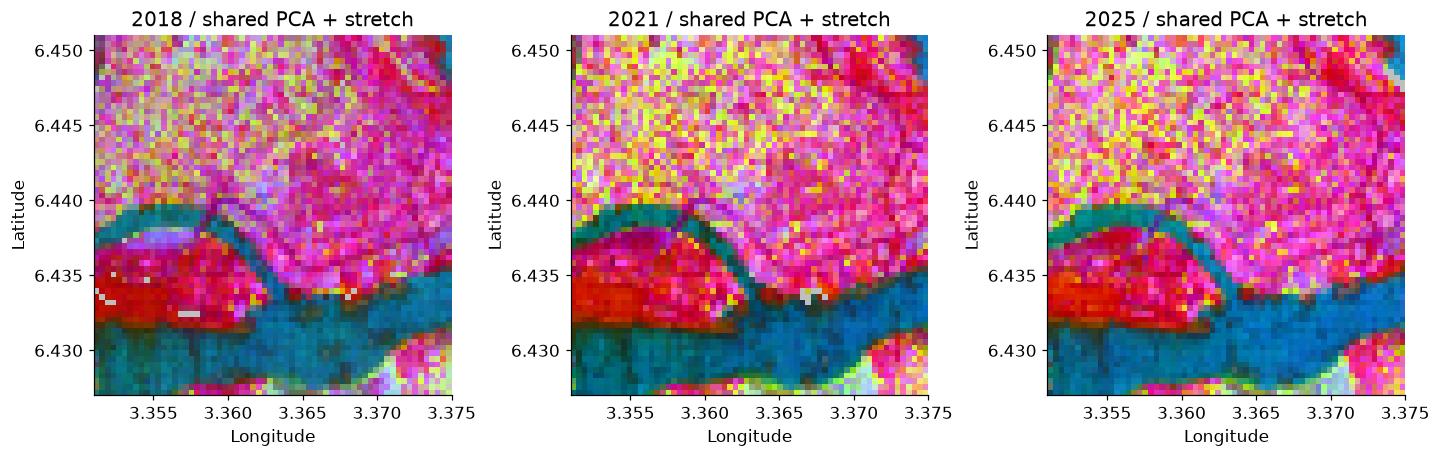

In [2]:
from tessera import load_tessera, unit_vectors, fit_pca, project, rgb_limits, rgb
d=load_tessera('lagos'); U=unit_vectors(d['embedding'])
model=fit_pca(U[-1],n=3)
scores=project(U,model)
limits=rgb_limits(scores[-1])  # one 2nd-to-98th percentile display stretch
colors=rgb(scores,limits)
print('Valid training vectors:',model['count'])
print('Explained variance per component:',np.round(model['explained'],4))
print('Total retained in this 3D display:',f"{model['explained'].sum():.1%}")
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
half=.000375/2
extent=[d['lon'][0]-half,d['lon'][-1]+half,d['lat'][-1]-half,d['lat'][0]+half]
for i,ax in enumerate(axes):
    ax.imshow(colors[i],extent=extent,origin='upper')
    ax.set(title=f'{d["years"][i]} / shared PCA + stretch',xlabel='Longitude',ylabel='Latitude')
    ax.set_aspect(1/np.cos(np.deg2rad(d['city']['center'][1])))
plt.show()

Gray pixels have missing vectors. Each RGB channel is one stretched principal component. Saturated colors can hide
differences outside the display range. Similar colors only mean proximity in the three displayed components, which omit the rest.

## 2. Rotate the question: geography versus feature space

This 3D scatter places points by principal-component scores. **None of its axes is longitude, latitude, or altitude.**
We use the same colors as the geographic map to connect the views. The plotted sample is every fourth valid point for readability.

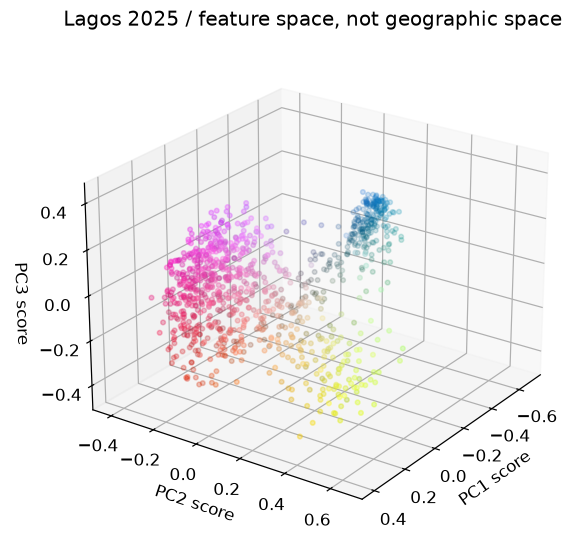

In [3]:
valid=np.isfinite(scores[-1]).all(axis=-1)
points=scores[-1][valid][::4]; point_colors=colors[-1][valid][::4]
fig=plt.figure(figsize=(9,6));ax=fig.add_subplot(111,projection='3d')
ax.scatter(points[:,0],points[:,1],points[:,2],c=point_colors,s=9,alpha=.65)
ax.set(xlabel='PC1 score',ylabel='PC2 score',zlabel='PC3 score',
       title='Lagos 2025 / feature space, not geographic space')
ax.view_init(elev=24,azim=35);plt.show()

## 3. Measure the information discarded

Reconstruct the normalized vectors using three components and compare with the originals. The residual norm measures
projection loss in this representation; it is not uncertainty in land cover or a physical measurement error.

Median reconstruction residual: 0.37081528792660856


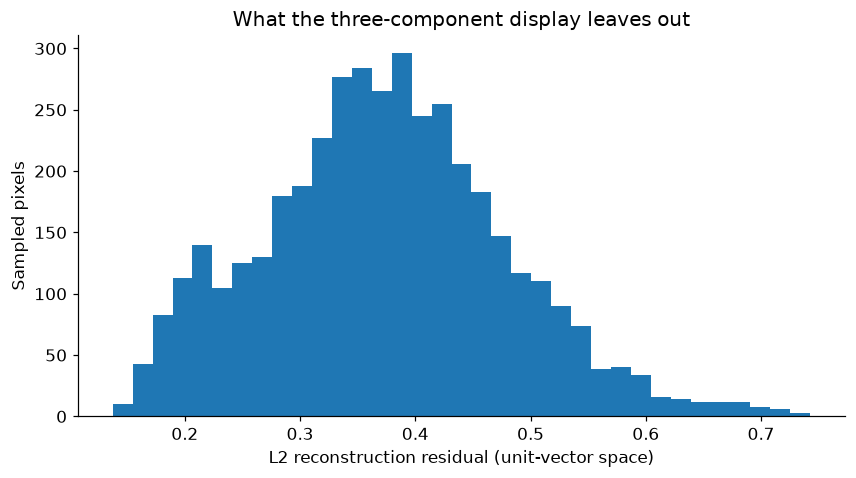

In [4]:
reconstructed=scores[-1]@model['components'].T+model['mean']
residual=np.linalg.norm(U[-1]-reconstructed,axis=-1)
print('Median reconstruction residual:',float(np.nanmedian(residual)))
fig,ax=plt.subplots();ax.hist(residual[np.isfinite(residual)],bins=35)
ax.set(xlabel='L2 reconstruction residual (unit-vector space)',ylabel='Sampled pixels',
       title='What the three-component display leaves out');plt.show()

## 4. Make a small animation without video software

The following player cycles through annual embedding displays using the fixed basis and stretch. It is not a movie of events
between the sampled years. Read the year labels: the intervals are unequal, and no intermediate years are interpolated.
The static maps above provide the same information when animation is unavailable.

In [5]:
from matplotlib.animation import FuncAnimation
fig,ax=plt.subplots(figsize=(5,5))
im=ax.imshow(colors[0],origin='upper');ax.set_axis_off()
def frame(i):
    im.set_data(colors[i]);ax.set_title(f'Lagos {d["years"][i]} | annual PCA display')
    return (im,)
animation=FuncAnimation(fig,frame,frames=len(d['years']),interval=1200,blit=False)
player=animation.to_jshtml(default_mode='once')
plt.close(fig)
display(HTML(player))

## Try it yourself

Fit 2, 8 and 16 components and compare retained variance and reconstruction residuals. Then apply the Lagos model to Abidjan with the same color limits; explain why that is a transfer experiment.

## Check your reasoning

PCA optimizes variance in its training sample. More components retain more information, but a visually clear plot does not establish semantic accuracy or transferability.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [TESSERA project](https://geotessera.org/) and [model repository](https://github.com/ucam-eo/tessera), University of Cambridge and collaborators.
- [Feng et al., TESSERA: Temporal Embeddings of Surface Spectra for Earth Representation and Analysis](https://doi.org/10.48550/arXiv.2506.20380), 2025, revised 2026.
- [GeoTessera Python client](https://github.com/ucam-eo/geotessera), MIT; pinned preparation commit in the provenance.
- [dClimate global-store documentation](https://github.com/dClimate/tessera-embeddings/blob/main/docs/global-store.md): annual v1.1-dclimate embeddings and observation counts.
- [Bundled source snapshot, coordinates, transformations and checksums](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/tessera-provenance.json). Embedding data: CC0-1.0; [upstream terms and advisory guidelines](https://github.com/ucam-eo/tessera/blob/master/aup.md).

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [6]:
print('LESSON COMPLETE: 19_tessera_pca')

LESSON COMPLETE: 19_tessera_pca
